# LM7 Lab — Multivariable Calculus and Lagrange Multipliers

Companion notebook to **From Calculus to Kelly, LM7**. It rebuilds the module's exhibits and computational examples from verified price files, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series for 0050 and 00679B: verification, dividends, split, common dates |
| 2 | The case (Exhibit 1), statistics by year (Exhibit 6), correlation at three frequencies, rolling correlation (Exhibit 7) |
| 3 | Partial derivatives: 00679B in 2022 (Example 1), the covariance identities, marginal variance (Example 2), Taylor attribution (Exhibit 2) |
| 4 | The growth function: gradient and Hessian at zero, exact vs quadratic model and where the gap comes from (Exhibit 3) |
| 5 | Classifying critical points (Example 3) |
| 6 | Lagrange multipliers solved symbolically and numerically (Example 4, Example 5) |
| 7 | Two-asset portfolios: level curves and the budget line (Exhibit 5), minimum variance in and out of sample, tangency and Kelly (Example 6, Example 7, Exhibit 8, Exhibit 9) |
| 8 | KKT: equity floor and leverage cap (Example 8, Exhibit 10) |
| 9 | Numerical gradients, Newton vs gradient ascent (Exhibit 11) |
| 10 | Practice-problem solutions and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

The fetch script reads your token from the `FINMIND_TOKEN` environment variable and checks every file against `data/raw_manifest.json`. `data/` then holds the windows the book retrieved on 2026-10-10: FinMind `TaiwanStockPrice` closes (with FinMind's `spread` column) for 0050 and 00679B, and their cash dividends from `TaiwanStockDividendResult`. Prices are unadjusted; Part 1 handles dividends and the 0050 split explicitly. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** Daily simple total returns between consecutive common trading dates from the base date 2017-01-17; moments with divisor $T$; annualization with $A=T/\text{years}=243.0543$ trading sessions a year (years = calendar days / 365.25), kept unrounded in every computation; an illustrative $r_f=1.5\%$ for tangency and Kelly, $r_f/A$ a day.

In [1]:
from pathlib import Path
from datetime import date
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
BASE, RF = "2017-01-17", 0.015
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Total-return series

* Every close must satisfy `close[t] − close[t−1] = spread[t]`. FinMind prints `spread = 0` on ex-dividend days and uses the split-adjusted reference on 0050's split day (4-for-1, **2025-06-18**), so those are the only mismatches allowed.
* 00679B has **37** ex-dates in the window. On two of them (2019-03-05 and 2025-08-21) the close did not change, so they produce no mismatch — but their dividends must still be paid. We therefore apply dividends from the dividend file on every ex-date and check that the previous close equals FinMind's `before_price`.
* Each fund's total-return index is built on its own calendar; returns are taken between consecutive **common** dates (0050 was halted 2025-06-11..17 while 00679B traded).

In [2]:
SPLITS = {"0050": ("2025-06-18", 4.0)}

def load(sym):
    raw = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    div = pl.read_csv(DATA / f"{sym}_dividends.csv").filter(pl.col("date") > raw["date"][0])
    chk = (raw.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap"))
              .filter(pl.col("gap") > 0.005))
    sdate = SPLITS.get(sym, (None, 1.0))[0]
    allowed = set(div["date"]) | ({sdate} if sdate else set())
    unexplained = sorted(set(chk["date"]) - allowed)
    silent = sorted(set(div["date"]) - set(chk["date"]))
    prev = raw.with_columns(pl.col("close").shift(1).alias("prev")).join(div, on="date", how="inner")
    assert prev.height == div.height, "an ex-date is not a trading date"
    assert (prev["prev"] - prev["before_price"]).abs().max() < 1e-9, "previous close != before_price"
    print(f"{sym}: {raw.height} rows {raw['date'][0]} -> {raw['date'][-1]}; ex-dates {div.height}; "
          f"mismatches {chk.height}; unexplained {unexplained}; ex-dates without mismatch {silent}")
    assert not unexplained
    return raw, div

def tr_index(sym):
    raw, div = load(sym)
    sdate, k = SPLITS.get(sym, ("", 1.0))
    return (raw.join(div.select("date", pl.col("cash_dividend").alias("D")), on="date", how="left")
               .sort("date")
               .with_columns(pl.col("D").fill_null(0.0),
                             pl.when(pl.col("date") == pl.lit(sdate)).then(pl.lit(k)).otherwise(pl.lit(1.0)).alias("k"))
               .with_columns(((pl.col("close") + pl.col("D")) / (pl.col("close").shift(1) / pl.col("k"))).fill_null(1.0).alias("G"))
               .select("date", pl.col("G").cum_prod().alias(f"I_{sym}")))

idx = (tr_index("0050").join(tr_index("00679B"), on="date", how="inner")
          .filter(pl.col("date") >= pl.lit(BASE)).sort("date")
          .with_columns(pl.col("I_0050") / pl.col("I_0050").first(), pl.col("I_00679B") / pl.col("I_00679B").first()))
ret = (idx.with_columns((pl.col("I_0050") / pl.col("I_0050").shift(1) - 1).alias("R1"),
                        (pl.col("I_00679B") / pl.col("I_00679B").shift(1) - 1).alias("R2"))
          .drop_nulls("R1").with_columns(pl.col("date").str.to_date()))
R1, R2 = ret["R1"].to_numpy(), ret["R2"].to_numpy()
T = len(R1)
dates = ret["date"].to_list()
years = (dates[-1] - date.fromisoformat(BASE)).days / 365.25
A = T / years
yr = ret["date"].dt.year().to_numpy()
IS, OOS, ALL = yr <= 2021, yr >= 2022, np.ones(T, bool)
print(f"T = {T} returns, {dates[0]} -> {dates[-1]}, years = {years:.6f}, A = {A:.4f} (= 2363 x 365.25 / 3551)")
print(f"growth: 0050 x{np.prod(1 + R1):.4f}, 00679B x{np.prod(1 + R2):.4f}")
assert T == 2363

0050: 2907 rows 2014-10-31 -> 2026-10-08; ex-dates 22; mismatches 23; unexplained []; ex-dates without mismatch []
00679B: 2369 rows 2017-01-17 -> 2026-10-08; ex-dates 37; mismatches 35; unexplained []; ex-dates without mismatch ['2019-03-05', '2025-08-21']
T = 2363 returns, 2017-01-18 -> 2026-10-08, years = 9.722108, A = 243.0543 (= 2363 x 365.25 / 3551)
growth: 0050 x8.6733, 00679B x0.8267


## Part 2 — The case, statistics by year, and correlation at three frequencies

`est(mask)` returns annualized population moments and every two-asset quantity used in the module: the minimum-variance weight (7.7) and volatility (7.8), the multiplier $\lambda^*=2\sigma_{\min}^2$, the Kelly fractions (7.12), the tangency weights (7.10) and $\mathrm{SR}^*$ (7.11).

In [3]:
def est(m, rf=RF):
    a, b = R1[m], R2[m]
    S = np.cov(np.vstack([a, b]), ddof=0) * A
    s1, s2, c = math.sqrt(S[0, 0]), math.sqrt(S[1, 1]), S[0, 1]
    sd2 = S[0, 0] + S[1, 1] - 2 * c                              # sigma_d^2 = Var(R1 - R2), annualized
    w = (S[1, 1] - c) / sd2
    vmin = (S[0, 0] * S[1, 1] - c * c) / sd2
    e = np.array([A * a.mean() - rf, A * b.mean() - rf])
    f = np.linalg.solve(S, e)                                    # Kelly fractions, eq. (7.12)
    sr = e / np.array([s1, s2]); rho = c / (s1 * s2)
    return dict(n=int(m.sum()), s1=s1, s2=s2, cov=c, rho=rho, w_mv=w, s_mv=math.sqrt(vmin), lam=2 * vmin, sd2=sd2,
                e1=e[0], e2=e[1], f1=f[0], f2=f[1], lev=f.sum(), wT1=f[0] / f.sum(),
                sr_star=math.sqrt((sr[0]**2 + sr[1]**2 - 2 * rho * sr[0] * sr[1]) / (1 - rho**2)),
                ret1=np.prod(1 + a) - 1, ret2=np.prod(1 + b) - 1, S=S)

E = {"full": est(ALL), "2017–2021": est(IS), "2022–2026": est(OOS)}
w_is = E["2017–2021"]["w_mv"]
vol = lambda x: math.sqrt(A * x.var())
mix = lambda w, m: w * R1[m] + (1 - w) * R2[m]
case = pl.DataFrame([{"window": k, "days": v["n"], "0050 return": v["ret1"], "00679B return": v["ret2"], "sigma_0050": v["s1"],
                      "sigma_00679B": v["s2"], "rho": v["rho"], "w_min_var": v["w_mv"], "sigma_min": v["s_mv"],
                      "vol of 42.3/57.7 mix": vol(mix(w_is, m))} for (k, v), m in zip(E.items(), (ALL, IS, OOS))])
case   # Exhibit 1

window,days,0050 return,00679B return,sigma_0050,sigma_00679B,rho,w_min_var,sigma_min,vol of 42.3/57.7 mix
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""full""",2363,7.673295,-0.173251,0.201060,0.134959,-0.105632,0.327476,0.106352,0.109088
"""2017–2021""",1213,1.380383,0.156072,0.163706,0.135475,-0.221314,0.423174,0.092248,0.092248
"""2022–2026""",1150,2.643655,-0.284864,0.234031,0.134335,-0.021900,0.252507,0.115392,0.124404


In [4]:
label = {2017: "2017 (from 17 Jan)", 2026: "2026 (to 8 Oct)"}
years_tbl = pl.DataFrame([{"year": label.get(y, str(y)), "days": int((yr == y).sum()), "0050": est(yr == y)["ret1"],
                           "00679B": est(yr == y)["ret2"], "sigma_0050": est(yr == y)["s1"], "sigma_00679B": est(yr == y)["s2"],
                           "rho": est(yr == y)["rho"], "w_min_var": est(yr == y)["w_mv"]} for y in range(2017, 2027)])
years_tbl   # Exhibit 6

year,days,0050,00679B,sigma_0050,sigma_00679B,rho,w_min_var
str,i64,f64,f64,f64,f64,f64,f64
"""2017 (from 17 Jan)""",235,0.173168,-0.002177,0.092614,0.083862,-0.036140,0.452246
"""2018""",247,-0.049511,0.006901,0.163077,0.089979,-0.394151,0.300055
"""2019""",242,0.335157,0.137072,0.121920,0.122277,-0.433889,0.501018
"""2020""",245,0.310844,0.081298,0.227989,0.213104,-0.166282,0.471090
"""2021""",244,0.219709,-0.064139,0.175505,0.125462,-0.174298,0.361104
"""2022""",246,-0.213416,-0.220919,0.216474,0.160785,-0.063255,0.363781
"""2023""",239,0.273978,0.031084,0.139424,0.126117,0.198984,0.437672
"""2024""",242,0.486715,-0.029009,0.246261,0.110316,-0.241219,0.217908
"""2025""",238,0.368534,-0.006222,0.245468,0.157322,0.009924,0.289263


 1w: n=502  2017-2021 -0.15   2022-2026 +0.09
1mo: n=118  2017-2021 -0.29   2022-2026 +0.21
lead-lag: corr(R1_t, R2_t-1) = +0.023, corr(R1_t-1, R2_t) = -0.021
trailing 243-day correlation, windows ending from 2023: min -0.29 on 2025-04-07, max +0.25 on 2023-12-14


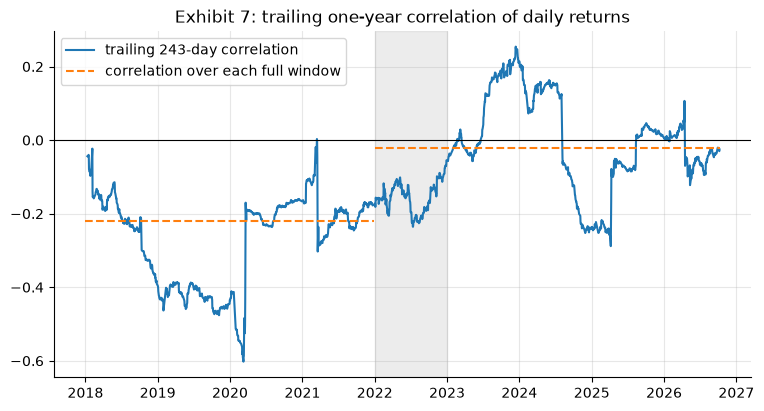

In [5]:
# correlation at weekly and monthly frequency, and lead-lag at daily frequency
lev = idx.with_columns(pl.col("date").str.to_date())
for every in ("1w", "1mo"):
    w = lev.group_by_dynamic("date", every=every).agg(pl.col("I_0050").last(), pl.col("I_00679B").last()).sort("date")
    a = np.concatenate([[1.0], w["I_0050"].to_numpy()]); b = np.concatenate([[1.0], w["I_00679B"].to_numpy()])
    r1, r2 = a[1:] / a[:-1] - 1, b[1:] / b[:-1] - 1
    yy = w["date"].dt.year().to_numpy()
    print(f"{every:>3}: n={len(r1)}  2017-2021 {np.corrcoef(r1[yy <= 2021], r2[yy <= 2021])[0, 1]:+.2f}   2022-2026 {np.corrcoef(r1[yy >= 2022], r2[yy >= 2022])[0, 1]:+.2f}")
print(f"lead-lag: corr(R1_t, R2_t-1) = {np.corrcoef(R1[1:], R2[:-1])[0, 1]:+.3f}, corr(R1_t-1, R2_t) = {np.corrcoef(R1[:-1], R2[1:])[0, 1]:+.3f}")

roll = ret.select("date", pl.rolling_corr(pl.col("R1"), pl.col("R2"), window_size=243).alias("rho_243")).drop_nulls()
late = roll.filter(pl.col("date") >= pl.lit(date(2023, 1, 1)))
lo, hi = late.sort("rho_243").row(0), late.sort("rho_243").row(-1)
print(f"trailing 243-day correlation, windows ending from 2023: min {lo[1]:+.2f} on {lo[0]}, max {hi[1]:+.2f} on {hi[0]}")
fig, ax = plt.subplots()
ax.plot(roll["date"], roll["rho_243"], label="trailing 243-day correlation")
ax.axvspan(date(2022, 1, 1), date(2022, 12, 31), color="grey", alpha=0.15)
ax.hlines([E["2017–2021"]["rho"], E["2022–2026"]["rho"]], [date(2018, 1, 1), date(2022, 1, 3)], [date(2021, 12, 30), date(2026, 10, 8)],
          colors="tab:orange", linestyles="dashed", label="correlation over each full window")
ax.axhline(0, color="black", lw=0.8); ax.set_title("Exhibit 7: trailing one-year correlation of daily returns"); ax.legend(); plt.show()

## Part 3 — Partial derivatives, the covariance identities and a Taylor attribution

**Example 1.** $h(x,y)=(1+x)(1+y)-1$ with USD/TWD from 27.690 to 30.708 in 2022 (central-bank close via CNA).
**Section 2's identities.** For $R_p=w_1R_1+w_2R_2$: $\operatorname{Var}(R_p)=w_1^2\sigma_1^2+2w_1w_2\sigma_{12}+w_2^2\sigma_2^2$, $\operatorname{Cov}(R_1,R_p)=w_1\sigma_1^2+w_2\sigma_{12}$, $\operatorname{Var}(R_1-R_2)=\sigma_1^2+\sigma_2^2-2\sigma_{12}$; they hold exactly for sample moments.
**Example 2.** Partial derivatives of $V(w_1,w_2)$ at 60/40 with full-sample moments.
**Exhibit 2.** First- and second-order Taylor terms of $V(\sigma_1,\sigma_2,\rho)=w_1^2\sigma_1^2+w_2^2\sigma_2^2+2w_1w_2\rho\sigma_1\sigma_2$ at fixed weights.

In [6]:
r22 = est(yr == 2022)["ret2"]; y = 30.708 / 27.690 - 1; x = (1 + r22) / (1 + y) - 1
print(f"Example 1: R_TWD {r22:.2%}, FX {y:.2%}, implied USD return {x:.2%}; h_x = {1 + y:.4f}, h_y = {1 + x:.4f}; "
      f"x + y = {x + y:.2%}, cross term {x * y:.2%}")

F = E["full"]; S = F["S"]; w = np.array([0.6, 0.4])
Rp = mix(0.6, ALL)
print("identities:", f"Var(Rp) {A * Rp.var():.6f} vs formula {w @ S @ w:.6f};",
      f"Cov(R1, Rp) {A * np.mean((R1 - R1.mean()) * (Rp - Rp.mean())):.6f} vs {(S @ w)[0]:.6f};",
      f"Var(R1 - R2) {A * (R1 - R2).var():.6f} vs {S[0, 0] + S[1, 1] - 2 * S[0, 1]:.6f}")
V = w @ S @ w; grad = 2 * S @ w
print(f"Example 2: V = {V:.6f}, sigma = {math.sqrt(V):.2%}, dV/dw = {grad.round(4)}, dsigma/dw = {(grad / (2 * math.sqrt(V))).round(3)}")
for step in (np.array([0.01, 0.0]), np.array([0.01, -0.01])):
    print(f"   step {step}: linear {grad @ step / (2 * math.sqrt(V)) * 100:.3f} pp, exact {(math.sqrt((w + step) @ S @ (w + step)) - math.sqrt(V)) * 100:.3f} pp")

Example 1: R_TWD -22.09%, FX 10.90%, implied USD return -29.75%; h_x = 1.1090, h_y = 0.7025; x + y = -18.85%, cross term -3.24%
identities: Var(Rp) 0.016092 vs formula 0.016092; Cov(R1, Rp) 0.023109 vs 0.023109; Var(R1 - R2) 0.064372 vs 0.064372
Example 2: V = 0.016092, sigma = 12.69%, dV/dw = [0.0462 0.0111], dsigma/dw = [0.182 0.044]
   step [0.01 0.  ]: linear 0.182 pp, exact 0.182 pp
   step [ 0.01 -0.01]: linear 0.138 pp, exact 0.140 pp


In [7]:
e0, e1 = E["2017–2021"], E["2022–2026"]
a, b, c = w_is**2, (1 - w_is)**2, 2 * w_is * (1 - w_is)
Vf = lambda s1, s2, r: a * s1**2 + b * s2**2 + c * r * s1 * s2
p0 = np.array([e0["s1"], e0["s2"], e0["rho"]]); d = np.array([e1["s1"], e1["s2"], e1["rho"]]) - p0
s1, s2, r = p0
grad = np.array([2 * a * s1 + c * r * s2, 2 * b * s2 + c * r * s1, c * s1 * s2])
H = np.array([[2 * a, c * r, c * s2], [c * r, 2 * b, c * s1], [c * s2, c * s1, 0.0]])
first = grad * d
exact = Vf(*(p0 + d)) - Vf(*p0)
print(f"weights {w_is:.3%} / {1 - w_is:.3%}; changes (decimal):", d.round(6), " partial derivatives at the start:", grad.round(6))
print("first-order terms (%^2):", (first * 1e4).round(2), " total", round(first.sum() * 1e4, 2))
print("second-order approximation (%^2):", round((first.sum() + 0.5 * d @ H @ d) * 1e4, 2), " exact:", round(exact * 1e4, 2))
print("third-order term (%^2):", round(c * d[0] * d[1] * d[2] * 1e4, 3), "  volatility", f"{math.sqrt(Vf(*p0)):.2%} -> {math.sqrt(Vf(*(p0 + d))):.2%}")

weights 42.317% / 57.683%; changes (decimal): [ 0.070325 -0.00114   0.199414]  partial derivatives at the start: [0.043994 0.072465 0.010827]
first-order terms (%^2): [30.94 -0.83 21.59]  total 51.7
second-order approximation (%^2): 69.74  exact: 69.67
third-order term (%^2): -0.078   volatility 9.22% -> 12.44%


## Part 4 — The growth function and its quadratic model (Exhibit 3)

$g(f_1,f_2)=A\cdot\frac1T\sum_t\ln(1+r_f/A+f_1X_{1t}+f_2X_{2t})$ with $X_i=R_i-r_f/A$; the model (7.3) is $r_f+f_1e_1+f_2e_2-\tfrac12(f_1^2\sigma_1^2+2f_1f_2\sigma_{12}+f_2^2\sigma_2^2)$.

Where does the gap come from? Exactly, $A\cdot\overline{R_p-R_p^2/2}$ equals (7.3) minus the dropped squared daily mean $\tfrac12A\bar R_p^{\,2}$, so model − exact = squared mean − (third + fourth + higher-order terms of $\ln(1+R_p)$), with third $=A\,\overline{R_p^3}/3$ and fourth $=-A\,\overline{R_p^4}/4$.

In [8]:
rd = RF / A                                                     # daily financing rate r_f/A
X = np.column_stack([R1, R2]) - rd

def g(f, m=ALL):
    return A * np.log1p(rd + X[m] @ np.asarray(f, float)).mean()

def g_model(f, e=F):
    f = np.asarray(f, float)
    return RF + f @ np.array([e["e1"], e["e2"]]) - 0.5 * f @ e["S"] @ f

def grad_hess(f, m=ALL):
    Xm = X[m]; wgt = 1 / (1 + rd + Xm @ np.asarray(f, float))
    return A * (Xm * wgt[:, None]).mean(0), -A * (Xm.T * wgt**2) @ Xm / len(Xm)

g0, H0 = grad_hess(np.zeros(2))
print("gradient at 0:", g0.round(4), " e =", np.round([F["e1"], F["e2"]], 4))
print("Hessian at 0:", H0.round(4).tolist(), " -Sigma =", (-F["S"]).round(4).tolist())

def terms(f):
    Rp = rd + X @ np.asarray(f, float)
    sq = A * Rp.mean()**2 / 2
    third, fourth = A * (Rp**3).mean() / 3, -A * (Rp**4).mean() / 4
    rest = g(f) - (g_model(f) - sq) - third - fourth
    return sq, third, fourth, rest

fstar = np.array([F["f1"], F["f2"]])
pts = {"0050 alone": (1, 0), "00679B alone": (0, 1), "min-var mix": (F["w_mv"], 1 - F["w_mv"]), "2 x 0050": (2, 0),
       "half Kelly": tuple(0.5 * fstar), "full Kelly (model)": tuple(fstar)}
rows = []
for k, v in pts.items():
    sq, t3, t4, t5 = terms(v)
    rows.append({"portfolio": k, "f1": v[0], "f2": v[1], "exact g": g(v), "model g": g_model(v),
                 "model - exact (bp)": (g_model(v) - g(v)) * 1e4, "squared mean (bp)": sq * 1e4,
                 "higher order (bp)": -(t3 + t4 + t5) * 1e4, "3rd (bp)": t3 * 1e4, "4th (bp)": t4 * 1e4, "5th+ (bp)": t5 * 1e4})
pl.DataFrame(rows)   # Exhibit 3, with the gap split into the squared daily mean and higher-order terms

gradient at 0: [ 0.2275 -0.0255]  e = [ 0.2275 -0.0255]
Hessian at 0: [[-0.0406, 0.0029], [0.0029, -0.0182]]  -Sigma = [[-0.0404, 0.0029], [0.0029, -0.0182]]


portfolio,f1,f2,exact g,model g,model - exact (bp),squared mean (bp),higher order (bp),3rd (bp),4th (bp),5th+ (bp)
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0050 alone""",1.000000,0.000000,0.222200,0.222297,0.972321,1.209830,-0.237509,0.426359,-0.189116,0.000265
"""00679B alone""",0.000000,1.000000,-0.019569,-0.019573,-0.038254,0.002253,-0.040508,0.086524,-0.046423,0.000407
"""min-var mix""",0.327476,0.672524,0.066705,0.066722,0.169625,0.107764,0.061861,-0.044157,-0.017570,-0.000134
"""2 x 0050""",2.000000,0.000000,0.388741,0.389168,4.276491,4.544620,-0.268129,3.310498,-3.025227,-0.017142
"""half Kelly""",2.795575,-0.259146,0.495495,0.496964,14.691301,8.896431,5.794870,6.280952,-11.697564,-0.378258
"""full Kelly (model)""",5.591150,-0.518292,0.637424,0.657619,201.954559,34.778659,167.175900,49.450094,-187.151793,-29.474201


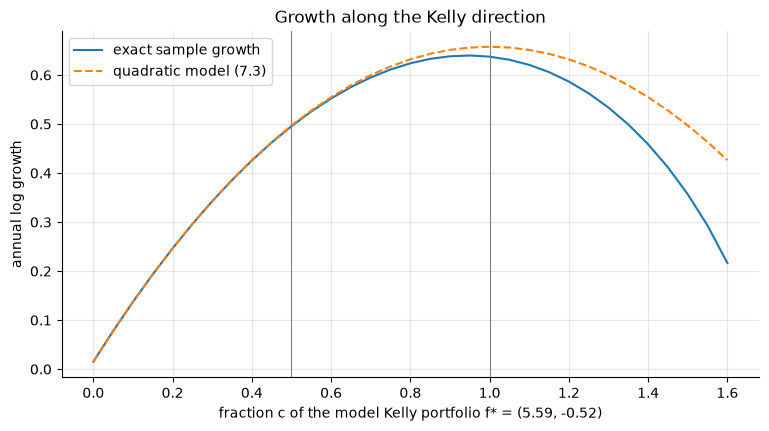

worst day at f*: -56.87% on 2025-04-07


In [9]:
cs = np.linspace(0, 1.6, 33)                                     # c = fraction of full Kelly (book-wide symbol)
fig, ax = plt.subplots()
ax.plot(cs, [g(c * fstar) for c in cs], label="exact sample growth")
ax.plot(cs, [g_model(c * fstar) for c in cs], "--", label="quadratic model (7.3)")
ax.axvline(0.5, color="grey", lw=0.8); ax.axvline(1.0, color="grey", lw=0.8)
ax.set_xlabel("fraction c of the model Kelly portfolio f* = (5.59, -0.52)"); ax.set_ylabel("annual log growth")
ax.set_title("Growth along the Kelly direction"); ax.legend(); plt.show()
worst = (rd + X @ fstar).min()
print(f"worst day at f*: {worst:.2%} on {dates[int(np.argmin(rd + X @ fstar))]}")

## Part 5 — Classifying critical points (Example 3)

In [10]:
import sympy as sp
xs, ys = sp.symbols("x y", real=True)
h = xs**3 - 3 * xs * ys + ys**3
crit = sp.solve([sp.diff(h, xs), sp.diff(h, ys)], [xs, ys], dict=True)
Hh = sp.hessian(h, (xs, ys))
for cp in crit:
    if all(v.is_real for v in cp.values()):
        Hc = Hh.subs(cp); D = Hc.det()
        kind = "saddle" if D < 0 else ("local min" if Hc[0, 0] > 0 else "local max") if D > 0 else "inconclusive"
        print(cp, " h =", h.subs(cp), " det H =", D, " ->", kind)

{x: 0, y: 0}  h = 0  det H = -9  -> saddle
{x: 1, y: 1}  h = -1  det H = 27  -> local min


## Part 6 — Lagrange multipliers, symbolically and numerically

**Example 4** (order split, illustrative $k_d=2$, $k_n=5$) and **Example 5** (risk budget across two strategies, illustrative figures). Each multiplier is checked against the shadow-price identity (7.6) by re-solving with the constraint relaxed. The variance budget is an ellipse, so the Lagrange conditions have two solutions: $\pm\mathbf f$ with $\pm\lambda$.

In [11]:
from scipy.optimize import minimize
xq, yq, lam, Q = sp.symbols("x y lambda Q", positive=True)
Lg = 2 * xq**2 + 5 * yq**2 - lam * (xq + yq - Q)
sol = sp.solve([sp.diff(Lg, v) for v in (xq, yq, lam)], [xq, yq, lam], dict=True)[0]
print("split:", {k: sp.simplify(v) for k, v in sol.items()}, " at Q=100:", {k: float(v.subs(Q, 100)) for k, v in sol.items()})
Cstar = sp.simplify((2 * xq**2 + 5 * yq**2).subs(sol))
print("C*(Q) =", Cstar, "  dC*/dQ at 100 =", float(sp.diff(Cstar, Q).subs(Q, 100)), "  C*(101)-C*(100) =", float(Cstar.subs(Q, 101) - Cstar.subs(Q, 100)))
print("integer split 71/29 cost:", 2 * 71**2 + 5 * 29**2, "   equal split:", 2 * 50**2 + 5 * 50**2)

split: {lambda: 20*Q/7, x: 5*Q/7, y: 2*Q/7}  at Q=100: {lambda: 285.7142857142857, x: 71.42857142857143, y: 28.571428571428573}
C*(Q) = 10*Q**2/7   dC*/dQ at 100 = 285.7142857142857   C*(101)-C*(100) = 287.14285714285717
integer split 71/29 cost: 14287    equal split: 17500


In [12]:
e = np.array([0.08, 0.03]); sd = np.array([0.16, 0.04]); rho_ = 0.2
Sg = np.array([[sd[0]**2, rho_ * sd[0] * sd[1]], [rho_ * sd[0] * sd[1], sd[1]**2]])
z = np.linalg.solve(Sg, e)                                       # direction Sigma^-1 e
for sgn in (1, -1):                                              # the two Lagrange candidates on the ellipse
    fc = sgn * 0.10 * z / math.sqrt(z @ Sg @ z)
    print(f"candidate {sgn:+d}: f = {fc.round(4)}, excess return {fc @ e:+.4%}, lambda = {(fc @ e) / (2 * 0.10**2):+.4f}")
def best(sigma_b):
    res = minimize(lambda f: -(f @ e), x0=[0.1, 1.0], method="SLSQP",
                   constraints=[{"type": "eq", "fun": lambda f: f @ Sg @ f - sigma_b**2}])
    return res.x, -res.fun
f10, E10 = best(0.10)
sr_star = math.sqrt(e @ z)
print(f"SLSQP maximum: exposures {f10.round(4)}, excess return {E10:.4%}, SR* = {sr_star:.4f}")
print(f"multiplier on the variance budget SR*/(2 sigma_b) = {sr_star / 0.2:.4f};  numerical dE*/d(sigma_b^2) = {(best(0.1001)[1] - best(0.0999)[1]) / (0.1001**2 - 0.0999**2):.4f}")
print(f"dE*/d sigma_b = {(best(0.11)[1] - E10) / 0.01:.4f}  (= SR*)")

candidate +1: f = [0.2743 2.0376], excess return +8.3073%, lambda = +4.1536
candidate -1: f = [-0.2743 -2.0376], excess return -8.3073%, lambda = -4.1536
SLSQP maximum: exposures [0.2743 2.0377], excess return 8.3073%, SR* = 0.8307
multiplier on the variance budget SR*/(2 sigma_b) = 4.1536;  numerical dE*/d(sigma_b^2) = 4.1539
dE*/d sigma_b = 0.8307  (= SR*)


## Part 7 — Two-asset portfolios: minimum variance in and out of sample, tangency and Kelly

In [13]:
e0, e1 = E["2017–2021"], E["2022–2026"]
realized = vol(mix(w_is, OOS))
print(f"Example 6: w* = {e0['w_mv']:.2%}, sigma_min = {e0['s_mv']:.2%}, lambda* = {e0['lam']:.4f}; realized in sample {vol(mix(w_is, IS)):.2%}")
print(f"out of sample: realized {realized:.2%}; ex-post w* = {e1['w_mv']:.2%} with {e1['s_mv']:.2%}; "
      f"sigma_d^2 = {e1['sd2']:.5f}, half the curvature V'' = 2 sigma_d^2 = {2 * e1['sd2']:.4f}")
pen = e1["sd2"] * (w_is - e1["w_mv"])**2
print(f"identity (7.9): {e1['s_mv']**2 * 1e4:.2f} + {pen * 1e4:.2f} = {(e1['s_mv']**2 + pen) * 1e4:.2f} %^2 vs realized^2 {realized**2 * 1e4:.2f}")
for dw in (0.05, 0.10):
    print(f"   weight error {dw:.2f}: +{(math.sqrt(e1['s_mv']**2 + e1['sd2'] * dw**2) - e1['s_mv']) * 100:.2f} pp")
env = 2 * e0["w_mv"] * (1 - e0["w_mv"]) * e0["s1"] * e0["s2"]
s1, s2, rr = e0["s1"], e0["s2"], e0["rho"] + 0.1
vb = (s1**2 * s2**2 - (rr * s1 * s2)**2) / (s1**2 + s2**2 - 2 * rr * s1 * s2)
print(f"envelope: d sigma_min^2/d rho = {env:.4f}; +0.1 -> predicted {0.1 * env:.5f}, exact {vb - e0['s_mv']**2:.5f}, sigma_min {math.sqrt(vb):.2%}")

Example 6: w* = 42.32%, sigma_min = 9.22%, lambda* = 0.0170; realized in sample 9.22%
out of sample: realized 12.44%; ex-post w* = 25.25% with 11.54%; sigma_d^2 = 0.07419, half the curvature V'' = 2 sigma_d^2 = 0.1484
identity (7.9): 133.15 + 21.61 = 154.76 %^2 vs realized^2 154.76
   weight error 0.05: +0.08 pp
   weight error 0.10: +0.32 pp
envelope: d sigma_min^2/d rho = 0.0108; +0.1 -> predicted 0.00108, exact 0.00108, sigma_min 9.79%


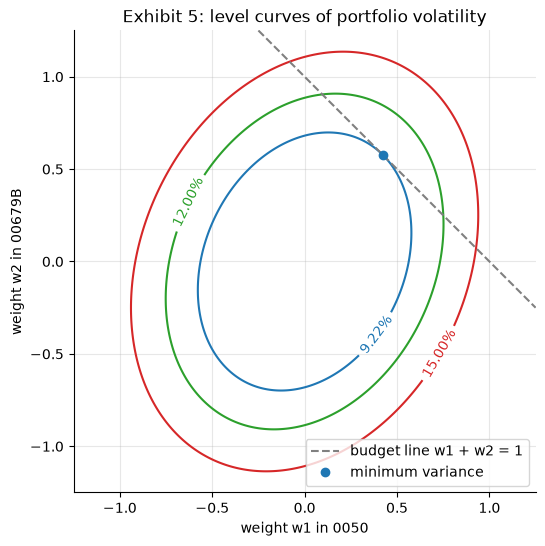

minimum variance at w = (42.3%, 57.7%), volatility 9.22%; grad V there: [0.017019 0.017019]; lambda* = 2 sigma_min^2 = 0.017019


In [14]:
# Exhibit 5: level curves of portfolio volatility in the (w1, w2) plane, 2017-2021 estimates, and the budget line
S0 = e0["S"]
grid = np.linspace(-1.25, 1.25, 251)
w1_, w2_ = np.meshgrid(grid, grid)
sig_ = np.sqrt(S0[0, 0] * w1_**2 + 2 * S0[0, 1] * w1_ * w2_ + S0[1, 1] * w2_**2)
fig, ax = plt.subplots(figsize=(6, 6))
cl = ax.contour(w1_, w2_, sig_, levels=[e0["s_mv"], 0.12, 0.15], colors=["tab:blue", "tab:green", "tab:red"])
ax.clabel(cl, fmt=lambda v: f"{v:.2%}")
ax.plot([-0.25, 1.25], [1.25, -0.25], "--", color="grey", label="budget line w1 + w2 = 1")
ax.plot([e0["w_mv"]], [1 - e0["w_mv"]], "o", color="tab:blue", label="minimum variance")
ax.set_aspect("equal"); ax.set_xlabel("weight w1 in 0050"); ax.set_ylabel("weight w2 in 00679B")
ax.set_title("Exhibit 5: level curves of portfolio volatility"); ax.legend(loc="lower right"); plt.show()
# where the smallest ellipse touches the line, grad V is parallel to grad psi = (1, 1): both entries equal lambda*
gV = 2 * S0 @ np.array([e0["w_mv"], 1 - e0["w_mv"]])
print(f"minimum variance at w = ({e0['w_mv']:.1%}, {1 - e0['w_mv']:.1%}), volatility {e0['s_mv']:.2%}; "
      f"grad V there: {gV.round(6)}; lambda* = 2 sigma_min^2 = {e0['lam']:.6f}")

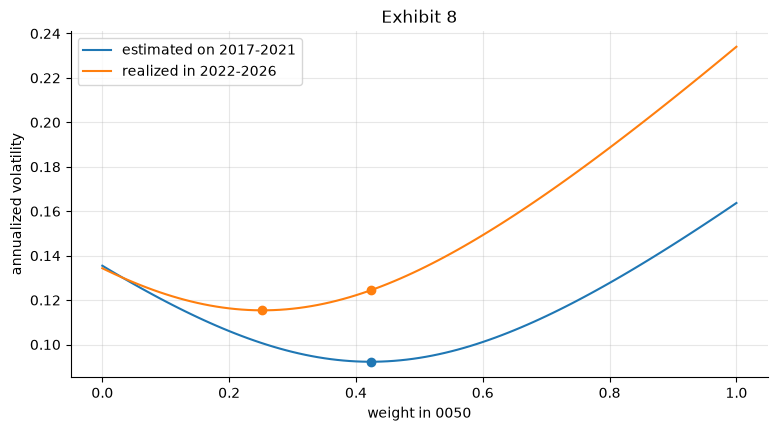

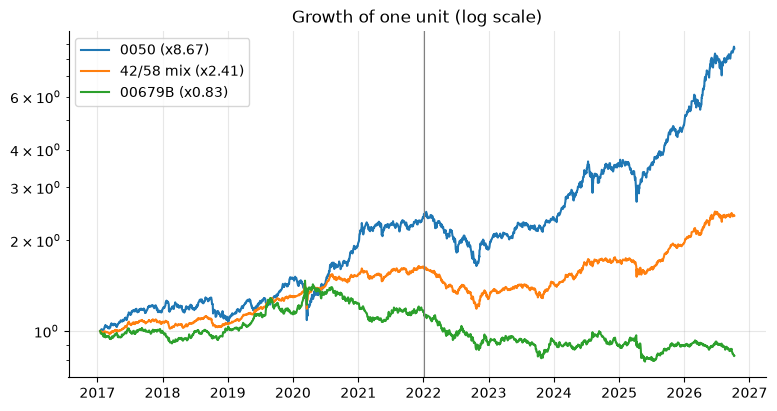

test window 2021-12-30 -> 2026-10-08 = 4.77 calendar years; compound growth a year: mix 8.67%, 0050 31.12%, 00679B -6.78%


In [15]:
ws = np.linspace(0, 1, 101)
vc = lambda e: np.sqrt(ws**2 * e["s1"]**2 + (1 - ws)**2 * e["s2"]**2 + 2 * ws * (1 - ws) * e["cov"])
fig, ax = plt.subplots()
ax.plot(ws, vc(e0), label="estimated on 2017-2021"); ax.plot(ws, vc(e1), label="realized in 2022-2026")
ax.plot([e0["w_mv"]], [e0["s_mv"]], "o", color="tab:blue"); ax.plot([e1["w_mv"]], [e1["s_mv"]], "o", color="tab:orange")
ax.plot([w_is], [realized], "o", color="tab:orange")
ax.set_xlabel("weight in 0050"); ax.set_ylabel("annualized volatility"); ax.set_title("Exhibit 8"); ax.legend(); plt.show()

W = lambda w: np.concatenate([[1.0], np.cumprod(1 + w * R1 + (1 - w) * R2)])
dts = [date.fromisoformat(BASE)] + dates
fig, ax = plt.subplots()
for w_, lab in ((1.0, "0050"), (w_is, "42/58 mix"), (0.0, "00679B")):
    ax.plot(dts, W(w_), label=f"{lab} (x{W(w_)[-1]:.2f})")
ax.set_yscale("log"); ax.axvline(date(2022, 1, 3), color="grey", lw=0.8); ax.set_title("Growth of one unit (log scale)"); ax.legend(); plt.show()
last_is = dates[int(np.flatnonzero(IS)[-1])]
yrs_oos = (dates[-1] - last_is).days / 365.25                   # calendar years, as AUTHORING 8 requires
cg = lambda x: np.prod(1 + x) ** (1 / yrs_oos) - 1
print(f"test window {last_is} -> {dates[-1]} = {yrs_oos:.2f} calendar years; compound growth a year: "
      f"mix {cg(mix(w_is, OOS)):.2%}, 0050 {cg(mix(1, OOS)):.2%}, 00679B {cg(mix(0, OOS)):.2%}")

In [16]:
kelly = pl.DataFrame([{"window": k, "e1": v["e1"], "e2": v["e2"], "s1": v["s1"], "s2": v["s2"], "rho": v["rho"], "f1": v["f1"], "f2": v["f2"],
                       "L": v["lev"], "wtan_0050": v["wT1"], "SR*": v["sr_star"]} for k, v in E.items()])
print(f"Example 7: det = {np.linalg.det(F['S']):.4e}; g* (model) = {RF + 0.5 * F['sr_star']**2:.2%}; exact g at f* = {g(fstar):.2%}")
yd = (last_is - date.fromisoformat(BASE)).days / 365.25          # calendar years of the estimation window (4.95)
print(f"standard error of the 2017-2021 mean over {yd:.2f} years: 0050 {e0['s1'] / math.sqrt(yd):.2%} against a mean of "
      f"{A * R1[IS].mean():.1%}; 00679B {e0['s2'] / math.sqrt(yd):.2%} against {A * R2[IS].mean():.1%}")
kelly   # Exhibit 9 (in-sample; not recommendations)

Example 7: det = 7.2809e-04; g* (model) = 65.76%; exact g at f* = 63.74%
standard error of the 2017-2021 mean over 4.95 years: 0050 7.36% against a mean of 18.7%; 00679B 6.09% against 3.8%


window,e1,e2,s1,s2,rho,f1,f2,L,wtan_0050,SR*
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""full""",0.227510,-0.025466,0.201060,0.134959,-0.105632,5.591150,-0.518292,5.072858,1.102170,1.133684
"""2017–2021""",0.172255,0.023196,0.163706,0.135475,-0.221314,7.001953,3.136410,10.138363,0.690639,1.130873
"""2022–2026""",0.285791,-0.076794,0.234031,0.134335,-0.021900,5.166981,-4.058375,1.108605,4.660794,1.337287


## Part 8 — KKT: equity floor and leverage cap (Example 8, Exhibit 10)

The cap $f_1+f_2\le2$ limits **net** exposure; it equals gross exposure $\lvert f_1\rvert+\lvert f_2\rvert$ only when both positions are long. With three constraints there are eight possible binding sets; all three cannot bind at once ($f_1=f_2=0$ breaks $f_1+f_2=2$), which leaves seven.

In [17]:
# knowledge check of Section 7: minimum variance with w1 >= 0.6 (full sample)
Vw = lambda w: w * w * S[0, 0] + (1 - w)**2 * S[1, 1] + 2 * w * (1 - w) * S[0, 1]
dV = 2 * S @ np.array([0.6, 0.4]); nu = dV[0] - dV[1]
print(f"floor binds (w* = {F['w_mv']:.1%}); nu = {nu:.4f}; vol {math.sqrt(Vw(0.6)):.2%} vs unconstrained {F['s_mv']:.2%}; "
      f"floor at 59%: dV predicted {-0.01 * nu:.6f}, exact {Vw(0.59) - Vw(0.6):.6f}")

# Example 8: enumerate every binding set for max g_model s.t. f1 + f2 <= 2 (nu_c), -f1 <= 0 (nu_1), -f2 <= 0 (nu_2)
ev = np.array([F["e1"], F["e2"]]); cap = 2.0
cons = {"cap": (np.array([1.0, 1.0]), cap), "f1>=0": (np.array([-1.0, 0.0]), 0.0), "f2>=0": (np.array([0.0, -1.0]), 0.0)}
name = {"cap": "nu_c", "f1>=0": "nu_1", "f2>=0": "nu_2"}
rows = []
for act in [(), ("cap",), ("f2>=0",), ("f1>=0",), ("cap", "f2>=0"), ("cap", "f1>=0"), ("f1>=0", "f2>=0"), ("cap", "f1>=0", "f2>=0")]:
    Aa = np.array([cons[c][0] for c in act]).reshape(len(act), 2)
    if np.linalg.matrix_rank(Aa) < len(act):
        print("binding set", act, "is inconsistent"); continue
    M = np.block([[S, Aa.T], [Aa, np.zeros((len(act), len(act)))]])
    sol = np.linalg.solve(M, np.concatenate([ev, [cons[c][1] for c in act]]))   # stationarity + binding constraints
    f, nus = sol[:2], sol[2:]
    rows.append({"binding": " and ".join(act) or "none", "f1": f[0], "f2": f[1],
                 "multipliers": ", ".join(f"{name[c]} = {v:.3f}" for c, v in zip(act, nus)) or "—",
                 "feasible": bool(f.sum() <= cap + 1e-9 and (f >= -1e-9).all()),
                 "multipliers >= 0": bool((nus >= -1e-12).all()), "gross exposure": float(abs(f).sum()), "model growth": g_model(f)})
kkt = pl.DataFrame(rows)
kkt   # Exhibit 10

floor binds (w* = 32.7%); nu = 0.0351; vol 12.69% vs unconstrained 10.64%; floor at 59%: dV predicted -0.000351, exact -0.000344
binding set ('cap', 'f1>=0', 'f2>=0') is inconsistent


binding,f1,f2,multipliers,feasible,multipliers >= 0,gross exposure,model growth
str,f64,f64,str,bool,bool,f64,f64
"""none""",5.591150,-0.518292,"""—""",false,true,6.109442,0.657619
"""cap""",4.584862,-2.584862,"""nu_c = 0.035""",false,true,7.169723,0.604219
"""f2>=0""",5.627898,-0.000000,"""nu_2 = 0.009""",false,true,5.627898,0.655200
"""f1>=0""",-0.000000,-1.398166,"""nu_1 = -0.224""",false,false,1.398166,0.032803
"""cap and f2>=0""",2.000000,-0.000000,"""nu_c = 0.147, nu_2 = 0.166""",true,true,2.000000,0.389168
"""cap and f1>=0""",0.000000,2.000000,"""nu_c = -0.062, nu_1 = -0.295""",true,false,2.000000,-0.072360
"""f1>=0 and f2>=0""",-0.000000,-0.000000,"""nu_1 = -0.228, nu_2 = 0.025""",true,false,0.000000,0.015000


In [18]:
gm = lambda f: g_model(np.asarray(f, float))
gr20 = ev - S @ np.array([2.0, 0.0])
nu_c, nu_2 = gr20[0], gr20[0] - gr20[1]
print(f"at (2, 0): nu_c = {nu_c:.4f}, nu_2 = {nu_2:.4f}, g_f2 = {gr20[1]:.4f}")
# the shadow price is a first-order value: exact model gains of a larger cap (the optimum stays at (cap, 0) up to 3)
for c_ in (2.1, 3.0):
    gc = ev - S @ np.array([c_, 0.0])
    assert gc[0] > 0 and gc[0] - gc[1] > 0                          # (c_, 0) still satisfies KKT
    print(f"   cap {c_}: optimum ({c_}, 0), exact model gain {(gm((c_, 0)) - gm((2, 0))) * 100:.2f} pp vs {nu_c * (c_ - 2) * 100:.2f} at first order")
print(f"net cap, f2 >= -0.01: (2.01, -0.01) gains {(gm((2.01, -0.01)) - gm((2, 0))) * 100:.4f} pp (0.01 x nu_2 = {0.01 * nu_2 * 100:.4f}); "
      f"the extra 0050 alone adds {(gm((2.01, 0)) - gm((2, 0))) * 100:.4f}, the short alone {(gm((2, -0.01)) - gm((2, 0))) * 100:.4f}")
print(f"gross cap |f1| + |f2| <= 2: (1.99, -0.01) changes growth by {(gm((1.99, -0.01)) - gm((2, 0))) * 100:+.3f} pp")
t = np.linspace(0, 1, 20001)                                     # the model's maximum on the gross-cap diamond
P = np.vstack([np.column_stack([2 * t, 2 * (1 - t)]), np.column_stack([2 * t, -2 * (1 - t)]),
               np.column_stack([-2 * t, 2 * (1 - t)]), np.column_stack([-2 * t, -2 * (1 - t)])])
gv = RF + P @ ev - 0.5 * np.einsum("ij,jk,ik->i", P, S, P)
print("gross-cap optimum:", P[int(np.argmax(gv))].round(4))

def kelly_capped(cap, fun=g):
    res = minimize(lambda f: -fun(f), x0=[0.5, 0.5], method="SLSQP", bounds=[(0, None), (0, None)],
                   constraints=[{"type": "ineq", "fun": lambda f: cap - f.sum()}])
    return res.x, -res.fun
for nm, fun in (("model", g_model), ("exact", g)):
    x2, g2 = kelly_capped(2.0, fun)
    nu_cap = (kelly_capped(2.01, fun)[1] - kelly_capped(1.99, fun)[1]) / 0.02
    print(f"{nm:5s}: f = {x2.round(4)}, growth {g2:.4%}, shadow price of the cap {nu_cap:.4f}")

at (2, 0): nu_c = 0.1467, nu_2 = 0.1664, g_f2 = -0.0197
   cap 2.1: optimum (2.1, 0), exact model gain 1.45 pp vs 1.47 at first order
   cap 3.0: optimum (3.0, 0), exact model gain 12.64 pp vs 14.67 at first order
net cap, f2 >= -0.01: (2.01, -0.01) gains 0.1661 pp (0.01 x nu_2 = 0.1664); the extra 0050 alone adds 0.1465, the short alone 0.0196
gross cap |f1| + |f2| <= 2: (1.99, -0.01) changes growth by -0.127 pp
gross-cap optimum: [2. 0.]
model: f = [2. 0.], growth 38.9168%, shadow price of the cap 0.1467
exact: f = [2. 0.], growth 38.8741%, shadow price of the cap 0.1461


## Part 9 — Numerical derivatives, Newton's method and gradient ascent (Exhibit 11)

The shortfall $g^*-g(\mathbf f_k)$ is computed as $A\cdot\overline{\ln\big((1+u^*)/(1+u_k)\big)}$, which does not subtract two nearly equal growth rates. Shortfalls below $10^{-10}$ are not shown: far smaller values approach the rounding error of the computed growth rate.

numerical gradient at 0: [ 0.2275 -0.0255]   numerical Hessian at 0: [[-0.0406, 0.0029], [0.0029, -0.0182]]
Newton path: [(0.0, 0.0), (5.5621, -0.5156), (5.3231, -0.2675), (5.3186, -0.2641), (5.3186, -0.2641)]  g* = 64.0296%
numerical gradient at the optimum: [-0.  0.]
smallest and largest curvature m, M: [0.01785 0.04079] = roots of x^2 - (s1^2 + s2^2) x + det: [0.01785 0.04079]
kappa 2.285, alpha 34.1068, model factor 0.39; curvatures at the optimum [0.0198 0.0493]
iterations to 1e-6: GA 18, Newton 2;  to 1e-10: GA 30, Newton 3
Newton shortfalls above the floor: ['6.3e-01', '2.4e-03', '7.0e-07']
worst day at the exact optimum: -53.69%


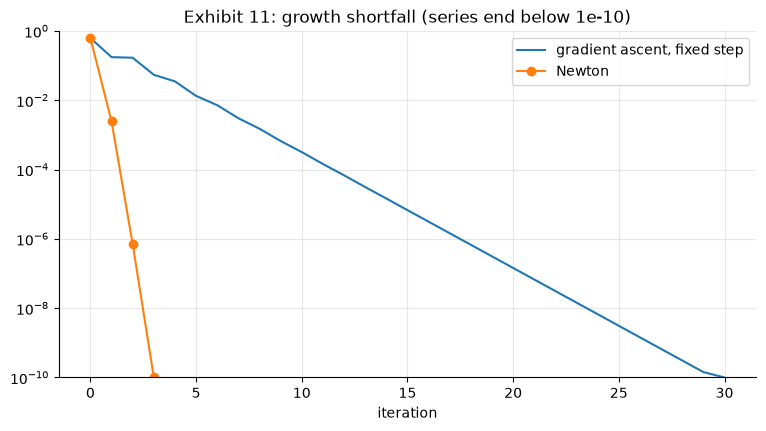

In [19]:
def num_grad(fun, x, d=1e-5):
    E_ = np.eye(len(x)); return np.array([(fun(x + d * E_[i]) - fun(x - d * E_[i])) / (2 * d) for i in range(len(x))])

def num_hess(fun, x, d=1e-4):
    E_, n = np.eye(len(x)), len(x)
    return np.array([[(fun(x + d*E_[i] + d*E_[j]) - fun(x + d*E_[i] - d*E_[j])
                       - fun(x - d*E_[i] + d*E_[j]) + fun(x - d*E_[i] - d*E_[j])) / (4 * d * d) for j in range(n)] for i in range(n)])

print("numerical gradient at 0:", num_grad(g, np.zeros(2)).round(4), "  numerical Hessian at 0:", num_hess(g, np.zeros(2)).round(4).tolist())
f = np.zeros(2); nt = [f.copy()]
for k in range(5):
    gr, Hh = grad_hess(f); f = f + np.linalg.solve(Hh, -gr); nt.append(f.copy())
fopt = nt[-1]; gopt = g(fopt)

def shortfall(f):
    du = X @ (fopt - np.asarray(f, float)); u = rd + X @ np.asarray(f, float)
    return A * np.log1p(du / (1 + u)).mean()

print("Newton path:", [tuple(float(v) for v in p.round(4)) for p in nt[:5]], f" g* = {gopt:.4%}")
print("numerical gradient at the optimum:", num_grad(g, fopt).round(8))
S_eig = np.linalg.eigvalsh(F["S"])
tr, det = F["S"][0, 0] + F["S"][1, 1], np.linalg.det(F["S"])
print("smallest and largest curvature m, M:", S_eig.round(5), "= roots of x^2 - (s1^2 + s2^2) x + det:",
      np.round([(tr - math.sqrt(tr**2 - 4 * det)) / 2, (tr + math.sqrt(tr**2 - 4 * det)) / 2], 5))
alpha_ = 2 / S_eig.sum()                                         # alpha = 2 / (m + M), about 34.1
f = np.zeros(2); ga = [shortfall(f)]
for k in range(60):
    f = f + alpha_ * grad_hess(f)[0]; ga.append(shortfall(f))
nt_gap = [shortfall(p) for p in nt]
first_below = lambda seq, tol: next(i for i, v in enumerate(seq) if v < tol)
print(f"kappa {S_eig[1] / S_eig[0]:.3f}, alpha {alpha_:.4f}, model factor {(S_eig[1] - S_eig[0]) / S_eig.sum():.2f}; "
      f"curvatures at the optimum {np.linalg.eigvalsh(-grad_hess(fopt)[1]).round(4)}")
print(f"iterations to 1e-6: GA {first_below(ga, 1e-6)}, Newton {first_below(nt_gap, 1e-6)};  to 1e-10: GA {first_below(ga, 1e-10)}, Newton {first_below(nt_gap, 1e-10)}")
print("Newton shortfalls above the floor:", [f"{v:.1e}" for v in nt_gap if v >= 1e-10])
print(f"worst day at the exact optimum: {(rd + X @ fopt).min():.2%}")
FLOOR = 1e-10
def to_floor(seq):
    out = []
    for v in seq:
        out.append(max(v, FLOOR))
        if v < FLOOR: break
    return out
fig, ax = plt.subplots()
ga_p, nt_p = to_floor(ga), to_floor(nt_gap)
ax.semilogy(range(len(ga_p)), ga_p, label="gradient ascent, fixed step")
ax.semilogy(range(len(nt_p)), nt_p, "o-", label="Newton")
ax.set_ylim(FLOOR, 1); ax.set_xlabel("iteration"); ax.set_title("Exhibit 11: growth shortfall (series end below 1e-10)"); ax.legend(); plt.show()

## Part 10 — Practice-problem solutions (computational)

In [20]:
def two(s1, s2, rho, e1=None, e2=None):
    c = rho * s1 * s2; sd2 = s1**2 + s2**2 - 2 * c
    out = {"w*": (s2**2 - c) / sd2, "sigma_min": math.sqrt((s1**2 * s2**2 - c * c) / sd2)}
    if e1 is not None:
        det = s1**2 * s2**2 - c * c; f1, f2 = (s2**2 * e1 - c * e2) / det, (s1**2 * e2 - c * e1) / det
        sr1, sr2 = e1 / s1, e2 / s2
        out.update(f1=f1, f2=f2, L=f1 + f2, wtan1=f1 / (f1 + f2), SR=math.sqrt((sr1**2 + sr2**2 - 2 * rho * sr1 * sr2) / (1 - rho**2)))
    return out

print("PP2 ", f"exact {0.95 * 1.03 - 1:.2%}, linear {-0.02:.2%}, cross {-0.05 * 0.03:.2%}, at 4%: {0.95 * 1.04 - 1:.2%}")
print("PP3 ", f"second-order {0.05 - 0.3**2 / 8:.4%}, exact {math.sqrt(1.2 * 0.9) - 1:.4%}")
print("PP4 ", [(p, p[0]**3 + p[1]**3 - 3 * p[0] - 12 * p[1] + 20, 36 * p[0] * p[1]) for p in ((1, 2), (-1, -2), (1, -2), (-1, 2))])
print("PP5 ", f"lambda* x db = {0.02 * 0.05:.4f}, exact {(1.05**2 - 1) * 0.01:.6f}; "
      f"distractors: B = 2 x 0.02 x 0.05 = {2 * 0.02 * 0.05:.4f} (lambda* read as sigma_min^2), C = 0.01 x 0.05 = {0.01 * 0.05:.4f}")
print("PP7/8", {k: round(v, 4) for k, v in two(0.20, 0.08, 0.25, 0.06, 0.02).items()}, f"g* = {0.02 + 0.5 * two(0.20, 0.08, 0.25, 0.06, 0.02)['SR']**2:.2%}")
p9 = two(0.20, 0.40, 0.95); c9 = 0.95 * 0.2 * 0.4
print("PP9 ", {k: round(v, 4) for k, v in p9.items()}, f"nu at w=1: {2 * (c9 - 0.04):.4f}")
g10 = lambda a, b: 0.10 * a + 0.04 * b - 0.5 * (0.04 * a * a + 0.01 * b * b)   # excess growth, rho = 0
for cap10 in (2.0, 3.0):
    f1c = (0.10 - 0.04 + 0.01 * cap10) / (0.04 + 0.01)
    print("PP10", f"cap {cap10}: ({f1c:.2f}, {cap10 - f1c:.2f}), nu_c = {0.10 - 0.04 * f1c:.3f}, excess growth {g10(f1c, cap10 - f1c):.2%}")
print("PP10", f"unconstrained (2.5, 4): {g10(2.5, 4):.2%}; raising the cap from 2 to 3 adds {(g10(1.8, 1.2) - g10(1.6, 0.4)) * 100:.2f} points")

PP2  exact -2.15%, linear -2.00%, cross -0.15%, at 4%: -1.20%
PP3  second-order 3.8750%, exact 3.9230%
PP4  [((1, 2), 2, 72), ((-1, -2), 38, 72), ((1, -2), 34, -72), ((-1, 2), 6, -72)]
PP5  lambda* x db = 0.0010, exact 0.001025; distractors: B = 2 x 0.02 x 0.05 = 0.0020 (lambda* read as sigma_min^2), C = 0.01 x 0.05 = 0.0005
PP7/8 {'w*': 0.0625, 'sigma_min': 0.0791, 'f1': 1.2667, 'f2': 2.3333, 'L': 3.6, 'wtan1': 0.3519, 'SR': 0.3502} g* = 8.13%
PP9  {'w*': 1.75, 'sigma_min': 0.114} nu at w=1: 0.0720
PP10 cap 2.0: (1.60, 0.40), nu_c = 0.036, excess growth 12.40%
PP10 cap 3.0: (1.80, 1.20), nu_c = 0.028, excess growth 15.60%
PP10 unconstrained (2.5, 4): 20.50%; raising the cap from 2 to 3 adds 3.20 points


In [21]:
# PP12: walk-forward, each year's minimum-variance weight held, rebalanced daily, through the following year,
# against a 50/50 mix also rebalanced daily and each year's own (ex-post) minimum-variance weight
rows = []
for y in range(2018, 2027):
    w_prev = est(yr == y - 1)["w_mv"]; cur = yr == y
    rows.append({"year": y, "w_prev": w_prev, "vol_prev_w": vol(mix(w_prev, cur)), "vol_50_50": vol(mix(0.5, cur)),
                 "vol_best": est(cur)["s_mv"]})
wf = pl.DataFrame(rows).with_columns((pl.col("vol_prev_w") < pl.col("vol_50_50")).alias("beats_50_50"))
print("years beating 50/50:", wf["beats_50_50"].sum(), "of", wf.height,
      "| simple averages of the nine annual volatilities:", {c: f"{wf[c].mean():.2%}" for c in ("vol_prev_w", "vol_50_50", "vol_best")})
r20 = wf.filter(pl.col("year") == 2020).row(0, named=True)
print(f"2020: {r20['vol_prev_w']:.3%} against {r20['vol_50_50']:.3%} for 50/50")
wf

years beating 50/50: 6 of 9 | simple averages of the nine annual volatilities: {'vol_prev_w': '10.84%', 'vol_50_50': '11.64%', 'vol_best': '10.07%'}
2020: 14.253% against 14.251% for 50/50


year,w_prev,vol_prev_w,vol_50_50,vol_best,beats_50_50
i64,f64,f64,f64,f64,bool
2018,0.452246,0.070731,0.076032,0.062702,true
2019,0.300055,0.077113,0.064960,0.064960,false
2020,0.501018,0.142532,0.142508,0.142175,false
2021,0.471090,0.096574,0.098573,0.093117,true
2022,0.361104,0.125088,0.130681,0.125086,true
2023,0.363781,0.103103,0.102886,0.102350,false
2024,0.437672,0.110632,0.122176,0.089943,true
2025,0.217908,0.134650,0.146433,0.133048,true
2026,0.289263,0.115020,0.163074,0.093159,true


### Extension: how long should the estimation window be?

Practice Problem 12 re-estimated the weight once a year from the previous calendar year. Generalize it. For estimation windows of 6, 12, 24 and 36 months, re-estimate the minimum-variance weight at the end of every month and hold it for the next month, computing returns daily. Compare the out-of-sample volatility of each rule with the 50/50 mix and with the full-sample weight (which uses future data). Then repeat with weekly instead of daily returns for estimation. Which window and which frequency would you have chosen, and how much of the gap to perfect foresight does each close? LM35 returns to this question with shrinkage estimators.

In [22]:
# starter: month-end rebalancing dates and a helper for one estimation window
month_ends = ret.group_by_dynamic("date", every="1mo").agg(pl.col("date").last().alias("d"))["d"].to_list()
def min_var_weight(mask):
    return est(mask)["w_mv"]
# for i, d in enumerate(month_ends[12:-1], start=12): ...  (your code)